# Figure 4 -- companion mass vs. period, coloured by reflex amplitude, with the $\mathrm{SNR_{tot}}$ loci (`simulated_planets_mass_period_snr_contours`)

Companion mass against orbital period for the four companion populations -- one- and two-companions
on the top row, their high-SNR selections below -- every point coloured by that companion's injected
reflex semimajor axis $\alpha$ [mas] on one shared log scale, with the DR4 baseline $T_{\rm baseline}$ (dashed) and
the $P_{\rm opt} = T_{\rm baseline}/\sqrt{2}$ period of the loci' minimum (dotted) marked and labelled on the lines. Circles
are inner companions, triangles outer ones. Over each panel run three loci of constant
$\mathrm{SNR_{tot}}$ (5, 10 and 30), each the companion mass at which *half the panel's own stars*
reach that signal.

The figure is the generator's `plot_simulated_planet_mass_period` with the loci of
`epochalypse_figures.draw_snr_lines` drawn on top, as in the original
`select_high_snr_by_threshold_500pc` notebook; both pieces are carried over verbatim apart from the
loaders. The inputs are the four truth tables in `catalog/data/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The populations

The loader asserts that each `_high_snr` table is exactly the $\mathrm{SNR_{tot}} \ge 5$ selection
of its parent.

In [2]:
populations = {}
for n in (1, 2):
    populations[(n, False)] = pf.read_population(n)
    populations[(n, True)] = pf.read_population(n, high_snr=True)
for key, frame in populations.items():
    print(f"  {pf.POPULATION_LABELS[key]:28s} {len(frame):>9,} systems")

  one-companion                5,040,328 systems
  one-companion, high-SNR        436,883 systems
  two-companions               5,040,328 systems
  two-companions, high-SNR        25,946 systems


## 2. The $\mathrm{SNR_{tot}}$ loci

$\mathrm{SNR_{tot}} = \sqrt{N}\,\alpha/\sigma_{\rm single}\,/\,[1 + (P/T)^2]$ is the catalog's own
detectability proxy, and the high-SNR populations are its $\ge 5$ selection. A locus of constant
$\mathrm{SNR_{tot}}$ in the mass--period plane is a V: $\alpha \propto M_p P^{2/3}$ makes it fall
inside the baseline and the $(P/T)^2$ suppression makes it rise beyond, with the minimum at
$P = T/\sqrt{2}$. `pf.snr_locus` solves the required companion mass **for every star of the panel**
at each trial period and takes the median, so the parallax / noise / transit-count spread of the
panel's own population survives into the curve rather than being replaced by median parameters.

The frames below carry the six columns the locus needs, in the characterization vocabulary
(`Mp_1_msun`, `a_1_au`, ...). The rebuilt $\mathrm{SNR_{tot}}$ is checked against the catalog's own
column before anything is drawn.

In [3]:
def locus_frame(frame, n_companions):
    out = pd.DataFrame({
        "period_1": frame["period" if n_companions == 1 else "period_1"].to_numpy(float),
        "Mp_1_msun": frame["mass_pl" if n_companions == 1 else "mass_pl_1"].to_numpy(float) * pf.MJUP,
        "a_1_au": frame["sma" if n_companions == 1 else "sma_1"].to_numpy(float),
        "alpha_1_mas": frame["alpha_mas" if n_companions == 1 else "alpha_1_mas"].to_numpy(float),
        "sigma_single_mas": frame["sigma_single_mas"].to_numpy(float),
        "n_transits_dr4": frame["n_transits_dr4"].to_numpy(float),
    })
    snr = frame["snr_total" if n_companions == 1 else "snr_total_1"].to_numpy(float)
    assert np.allclose(pf.snr_total(out.head(5000)), snr[:5000], rtol=1e-6), "SNR_tot not reproduced"
    return out


LOCUS = {key: locus_frame(frame, key[0]) for key, frame in populations.items()}

# The V's minimum, and the mass the SNR_tot = 5 locus sits at there for the median star of each panel
P_OPT = pf.BASELINE / np.sqrt(2)
print(f"P_opt = T/sqrt(2) = {P_OPT:.2f} yr")
for key, lf in LOCUS.items():
    m5 = pf.snr_locus(lf, 5.0, np.array([P_OPT]))[0] / pf.MJUP
    m10 = pf.snr_locus(lf, 10.0, np.array([P_OPT]))[0] / pf.MJUP
    lo, hi = pf.snr_locus(lf, 5.0, np.array([P_OPT]), quantile=(0.1, 0.9))[:, 0] / pf.MJUP
    print(f"  {pf.POPULATION_LABELS[key]:28s} SNR_tot = 5 at P_opt: median star {m5:6.2f} M_Jup "
          f"(10-90% of stars {lo:.2f}-{hi:.2f});  SNR_tot = 10: {m10:.2f} M_Jup")

P_opt = T/sqrt(2) = 3.89 yr
  one-companion                SNR_tot = 5 at P_opt: median star   5.23 M_Jup (10-90% of stars 2.06-9.50);  SNR_tot = 10: 10.52 M_Jup


  one-companion, high-SNR      SNR_tot = 5 at P_opt: median star   4.14 M_Jup (10-90% of stars 1.28-8.03);  SNR_tot = 10: 8.31 M_Jup
  two-companions               SNR_tot = 5 at P_opt: median star   5.23 M_Jup (10-90% of stars 2.06-9.50);  SNR_tot = 10: 10.52 M_Jup


  two-companions, high-SNR     SNR_tot = 5 at P_opt: median star   2.55 M_Jup (10-90% of stars 0.63-6.08);  SNR_tot = 10: 5.13 M_Jup


## 3. The figure

Random on the top row, high-SNR below. The two-companions panels draw both companions. Every panel
draws the same 10,000-system subsample (`pf.draw`, the shared seed) that Figure 7 draws, so the two
figures show the same clouds. Drawing the full tables instead reaches further into the tails -- the
one-companion high-SNR selection carries a few hundred companions below $0.5\,M_{\rm Jup}$ (0.04\%
of it) that a 10,000-system draw does not -- and made the two figures' lower edges disagree. The
loci are still computed over every star of each panel.


In [4]:
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.transforms import blended_transform_factory, offset_copy

PANELS = [(1, False), (2, False), (1, True), (2, True)]      # random on top, high-SNR below
N_MAP = 10_000                      # every panel draws the paper's shared subsample, as Fig. 7
DRAWN = {key: pf.draw(frame, N_MAP) for key, frame in populations.items()}
SNR_LINES = (5, 10, 30)             # 5 is the high-SNR floor, so it bounds the lower panels
SNR_FONTSIZE = 16
SNR_CORNER, SNR_CORNER_DY, SNR_CORNER_ANCHOR = (0.025, 0.965), 0.085, 0.25
LINE_LABEL_FONTSIZE, LINE_LABEL_DX, LINE_LABEL_Y = 15, 5, 0.03   # vertical-line labels: pt offset, axes-fraction floor


def plot_mass_period(stem, with_loci=True, paper=False):
    cmap = LinearSegmentedColormap.from_list(
        "rainbow_trunc", plt.get_cmap("rainbow")(np.linspace(0, 1, 256)))

    signatures = []
    for key in PANELS:
        frame = populations[key]
        if key[0] == 1:
            signatures.append(frame["alpha_mas"].to_numpy())
        else:
            signatures += [frame["alpha_1_mas"].to_numpy(), frame["alpha_2_mas"].to_numpy()]
    signatures = np.concatenate(signatures)
    signatures = signatures[np.isfinite(signatures) & (signatures > 0)]
    norm = LogNorm(vmin=np.quantile(signatures, 0.01), vmax=np.quantile(signatures, 0.99))

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
    fig.set_layout_engine("none")

    scatter = None
    for ax, key in zip(axes.flat, PANELS):
        frame = DRAWN[key]
        if key[0] == 1:
            scatter = ax.scatter(frame["period"], frame["mass_pl"], c=frame["alpha_mas"],
                                 norm=norm, cmap=cmap, s=27, alpha=0.65, linewidths=0,
                                 rasterized=True)
        else:
            scatter = ax.scatter(frame["period_1"], frame["mass_pl_1"], c=frame["alpha_1_mas"],
                                 norm=norm, cmap=cmap, marker="o", s=27, alpha=0.7,
                                 linewidths=0, rasterized=True)
            ax.scatter(frame["period_2"], frame["mass_pl_2"], c=frame["alpha_2_mas"],
                       norm=norm, cmap=cmap, marker="^", s=36, alpha=0.7, linewidths=0,
                       rasterized=True)
        ax.axvline(pf.BASELINE, color="k", ls="--", lw=2, zorder=7)
        ax.axvline(pf.BASELINE / np.sqrt(2), color="k", ls=":", lw=2, zorder=7)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(pf.POPULATION_LABELS[key].replace(", ", ": "), pad=12, fontsize=27)
        ax.grid(True, which="both", alpha=0.15)
        ax.tick_params(which="both", labelsize=16)

    for ax in axes[-1, :]:
        ax.set_xlabel("orbital period [yr]", fontsize=23)
    for ax in axes[:, 0]:
        ax.set_ylabel(r"companion mass [$M_{\rm Jup}$]", fontsize=23)

    fig.subplots_adjust(left=0.075, right=0.88, top=0.85, bottom=0.085, hspace=0.17, wspace=0.06)
    cax = fig.add_axes([0.905, 0.085, 0.02, 0.775])
    colorbar = fig.colorbar(scatter, cax=cax, orientation="vertical", extend="both")
    colorbar.set_label(r"stellar reflex semimajor axis $\alpha$ [mas]", fontsize=24)
    colorbar.ax.tick_params(labelsize=16)

    centre_x = 0.5 * (0.075 + 0.88)
    fig.suptitle(r"\texttt{epochalypse} injected companions", fontsize=36, x=centre_x, y=0.965)
    handles = [
        Line2D([0], [0], marker="o", color="0.35", lw=0, markersize=10, label="inner companion"),
        Line2D([0], [0], marker="^", color="0.35", lw=0, markersize=11, label="outer companion"),
    ]
    if with_loci:
        handles.append(Line2D([0], [0], color="k", lw=2.2,
                              label=r"constant $\mathrm{SNR}_{\rm tot}$ (median over stars)"))
    fig.legend(handles=handles, loc="center", bbox_to_anchor=(centre_x, 0.905),
               ncol=len(handles), frameon=False, fontsize=20, columnspacing=2.4, handlelength=1.8)

    # The two vertical lines are labelled on the line: the baseline to the right of its dashed
    # line, T/sqrt(2) to the left of its dotted one, both reading upwards from the panel floor.
    for ax in axes.flat:
        for x, text, side in ((pf.BASELINE, r"\textit{Gaia} DR4 baseline", +1),
                              (pf.BASELINE / np.sqrt(2),
                               r"$P_{\rm opt} = T_{\rm baseline}/\sqrt{2}$", -1)):
            transform = offset_copy(blended_transform_factory(ax.transData, ax.transAxes),
                                    fig=fig, units="points", x=side * LINE_LABEL_DX, y=0)
            ax.text(x, LINE_LABEL_Y, text, rotation=90, rotation_mode="anchor", ha="left",
                    va="top" if side > 0 else "bottom", fontsize=LINE_LABEL_FONTSIZE, color="k",
                    zorder=9, transform=transform,
                    bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="k", lw=0.8, alpha=0.92))

    if with_loci:
        # Freeze the limits first: the loci leave the top of the panel at short period, and the
        # axes are shared, so an autoscaling panel would rescale all four to fit them.
        for ax, key in zip(axes.flat, PANELS):
            ax.set_autoscale_on(False)
            ax_p = pf._axis("period_{k}", "orbital period [yr]", "log", ax.get_xlim())
            pf.draw_snr_lines(ax, LOCUS[key], SNR_LINES, ax_p, pf.AX_M, color="k", lw=2.2,
                              fontsize=SNR_FONTSIZE, mode=pf.SNR_LABEL_CORNER, corner=SNR_CORNER,
                              corner_dy=SNR_CORNER_DY, corner_anchor=SNR_CORNER_ANCHOR)
    pf.save(fig, stem, dpi=200, paper=paper)
    plt.close(fig)

### Without the loci

The figure as the generator writes it (`simulated_planets_mass_period`), for reference. The
bottom-right panel is the one to look at: with $\mathrm{SNR_{tot}} \ge 5$ required of **both**
companions, inner and outer land in the same detectability wedge.

  wrote analysis/supplementary_figures/simulated_planets_mass_period.pdf, analysis/supplementary_figures/simulated_planets_mass_period.png


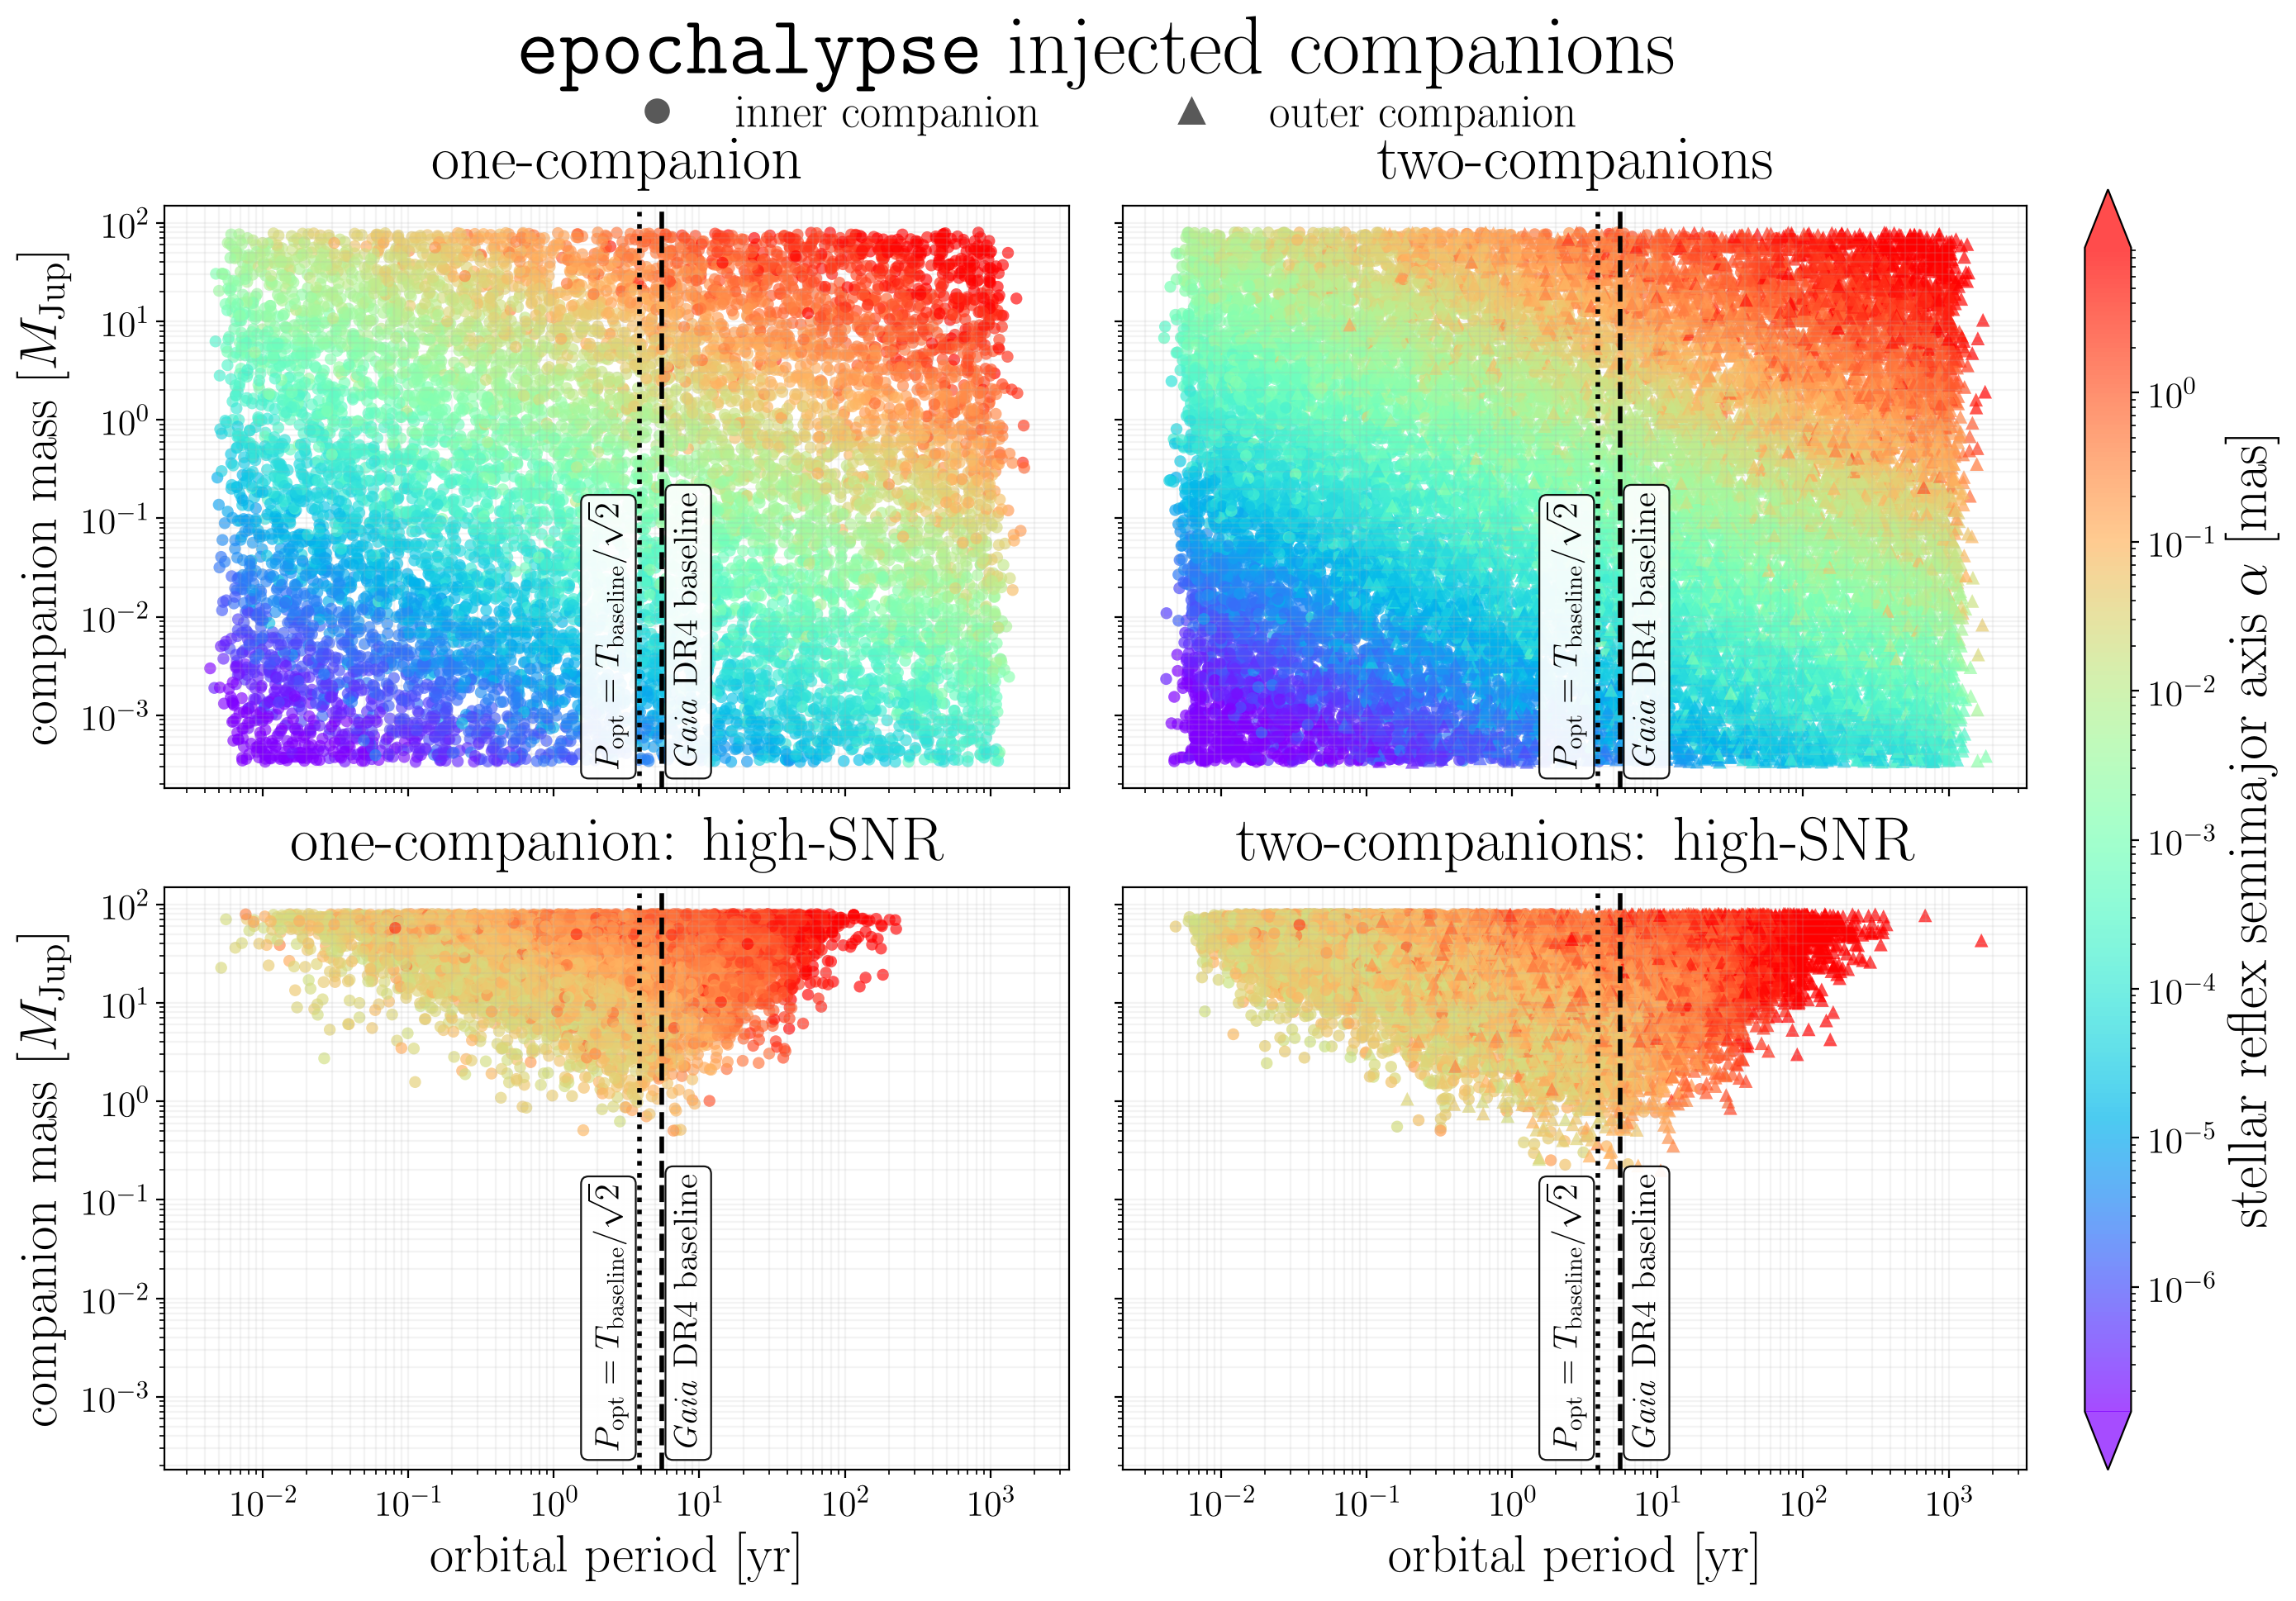

In [5]:
plot_mass_period("simulated_planets_mass_period", with_loci=False)
display(Image(filename=str(pf.SUPP_FIG_DIR / "simulated_planets_mass_period.png"), width=1000))

## 4. The paper figure

The same four panels with the $\mathrm{SNR_{tot}} = 5, 10, 30$ loci drawn on, each on its own
panel's stars. The selected clouds reach *below* their own floor: a locus is the median star, and the
edge of a population is set by its most favourable ones.

  wrote analysis/paper_figures/simulated_planets_mass_period_snr_contours.pdf, analysis/paper_figures/simulated_planets_mass_period_snr_contours.png


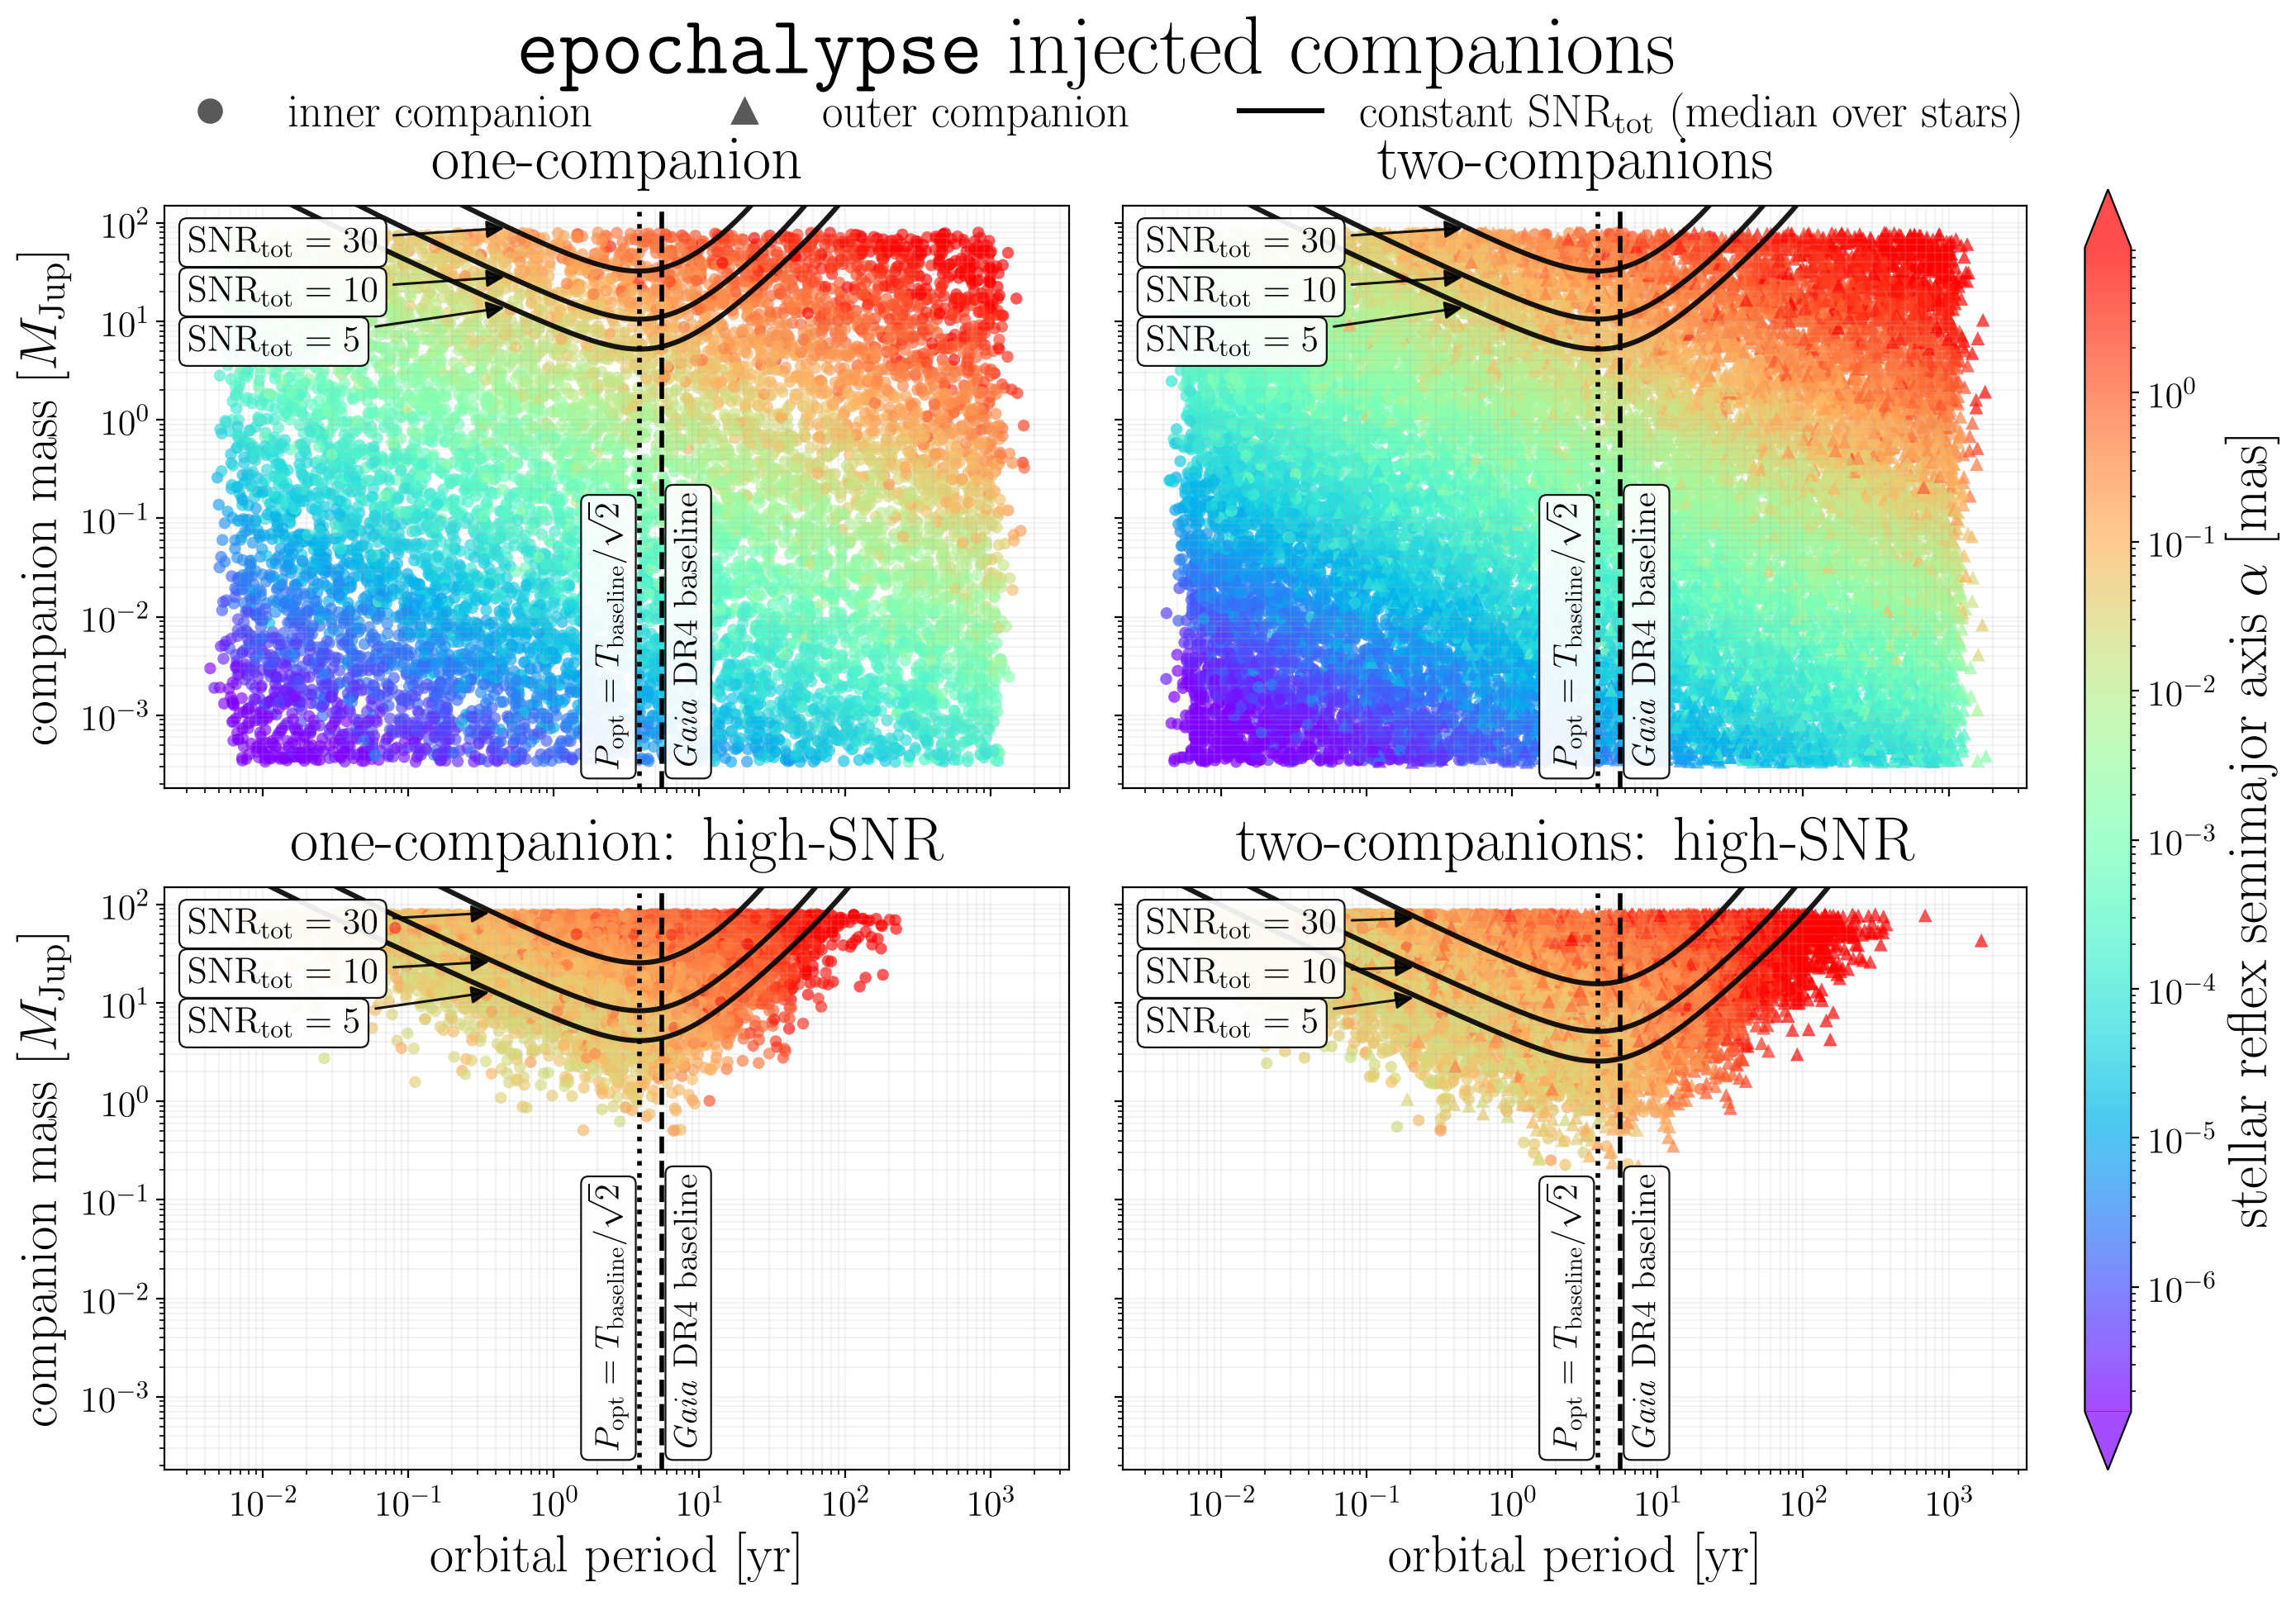

In [6]:
plot_mass_period("simulated_planets_mass_period_snr_contours", with_loci=True, paper=True)
display(Image(filename=str(pf.PAPER_FIG_DIR / "simulated_planets_mass_period_snr_contours.png"), width=1000))